# 01.9 · The EDA checklist

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/01-working-with-data/09-eda-checklist/lesson.ipynb)

Read the [README](README.md) first. We run the eight questions on the ten-row loyalty table (checking your hand answers), then on a real ShopWave customer table with a real target and a planted leak.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## 1. The loyalty table

In [2]:
import pandas as pd
loyalty = pd.DataFrame({
    "member":      range(1, 11),
    "age":         [34, 51, 29, None, 45, 38, 62, 23, 41, 33],
    "visits":      [12, 3, 40, 7, 0, 15, 22, 1, 9, 350],
    "country":     ["UK", "UK", "DE", "UK", "FR", "UK", "UK", "UK", "DE", "UK"],
    "joined":      pd.to_datetime(["2019-03", "2020-11", "2018-07", "2021-01", "2021-06", "2019-09", "2017-02", "2021-08", "2020-02", "2020-05"]),
    "upgraded_on": pd.to_datetime(["2021-05", None, "2019-01", None, None, None, "2018-03", None, None, None]),
    "premium":     [1, 0, 1, 0, 0, 0, 1, 0, 0, 0],
})
loyalty

,member,age,visits,country,joined,upgraded_on,premium
0,1,34.0,12,UK,2019-03-01,2021-05-01,1
1,2,51.0,3,UK,2020-11-01,NaT,0
2,3,29.0,40,DE,2018-07-01,2019-01-01,1
3,4,NaN,7,UK,2021-01-01,NaT,0
4,5,45.0,0,FR,2021-06-01,NaT,0
5,6,38.0,15,UK,2019-09-01,NaT,0
6,7,62.0,22,UK,2017-02-01,2018-03-01,1
7,8,23.0,1,UK,2021-08-01,NaT,0
8,9,41.0,9,DE,2020-02-01,NaT,0
9,10,33.0,350,UK,2020-05-01,NaT,0


In [3]:
def overview(df, target=None):
    """Checklist steps 1-5 in one call. Prints; returns nothing."""
    print(f"1. SHAPE      {df.shape[0]:,} rows × {df.shape[1]} columns")
    print("2. TYPES")
    types = pd.DataFrame({"dtype": df.dtypes.astype(str), "distinct": df.nunique()})
    print(types.to_string())
    miss = df.isna().mean().mul(100).round(1)
    print("3. MISSING %  " + (miss[miss > 0].to_dict().__repr__() if (miss > 0).any() else "none"))
    print(f"4. DUPLICATES {df.duplicated().sum():,} exact")
    if target is not None:
        t = df[target]
        if t.nunique() <= 10:
            print(f"5. TARGET     {t.value_counts(normalize=True).round(3).to_dict()}")
        else:
            print(f"5. TARGET     mean {t.mean():.1f}, median {t.median():.1f}, min {t.min():.1f}, max {t.max():.1f}, zeros {(t == 0).mean():.0%}")

In [4]:
overview(loyalty, target="premium")

1. SHAPE      10 rows × 7 columns
2. TYPES
                      dtype  distinct
member                int64        10
age                 float64         9
visits                int64        10
country                 str         3
joined       datetime64[us]        10
upgraded_on  datetime64[us]         3
premium               int64         2
3. MISSING %  {'age': 10.0, 'upgraded_on': 70.0}
4. DUPLICATES 0 exact
5. TARGET     {0: 0.7, 1: 0.3}


Steps 1–5 in one call. Now step 3 deserves a closer look: *where* is `upgraded_on` missing?

In [5]:
pd.crosstab(loyalty["upgraded_on"].isna(), loyalty["premium"], rownames=["upgraded_on missing"], colnames=["premium"])

premium,0,1
upgraded_on missing,,
False,0,3
True,7,0


Missing exactly when `premium = 0`. The column is filled in *after* the upgrade. At prediction time it is always empty. **Leakage: drop it.**

### Step 6: each feature alone

In [6]:
loyalty[["age", "visits"]].describe().round(1)

,age,visits
count,9.0,10.0
mean,39.6,45.9
std,11.9,107.5
min,23.0,0.0
25%,33.0,4.0
50%,38.0,10.5
75%,45.0,20.2
max,62.0,350.0


`visits` max 350 against a 75th percentile of 20: member 10 is an outlier to investigate, not delete.

### Step 7: features vs target

In [7]:
loyalty.groupby("premium")[["age", "visits"]].median()

,age,visits
premium,,
0,39.5,7.0
1,34.0,22.0


In [8]:
loyalty.assign(tenure_years=(pd.Timestamp("2022-01-01") - loyalty["joined"]).dt.days / 365).groupby("premium")["tenure_years"].median().round(1)

premium
0    1.2
1    3.5
Name: tenure_years, dtype: float64

Premium members visit more and joined earlier. Tenure is a feature worth building. Every finding matches the README's written summary.

## 2. The real data: a customer table with a time-based target

This is the pattern for every supervised problem in the course. **Features from the past, target from the future, a cut-off date between them.**

- Features: everything a customer did from Dec 2010 to 31 Aug 2011.
- Target: what they spent from 1 Sep to 30 Nov 2011 (`spend_next_quarter`), and whether they came back at all (`came_back`).

In [9]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()

(541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")

541,910 rows → 392,693 after cleaning


In [11]:
cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days

# target: what each customer spent in the next quarter (0 if they did not come back)
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["came_back"] = (cust["spend_next_quarter"] > 0).astype(int)

# a column "helpfully" added by the export: recency measured at export time (Dec 2011)
last_ever = sales.groupby("Customer ID")["InvoiceDate"].max()
cust["recency_days"] = (sales["InvoiceDate"].max() - last_ever).dt.days.reindex(cust.index)

cust = cust.drop(columns=["first_order", "last_order"])
print(cust.shape)
cust.head()

(3317, 11)


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter,came_back,recency_days
Customer ID,,,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00,0,325
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32,1,1
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00,1,74
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00,0,309
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23,1,35


### Steps 1–5

In [12]:
overview(cust, target="spend_next_quarter")

1. SHAPE      3,317 rows × 11 columns
2. TYPES
                      dtype  distinct
orders                int64        45
spend               float64      3248
products              int64       269
items                 int64      1363
country                 str        36
avg_order           float64      3245
tenure_days           int64       219
days_since_last       int64       218
spend_next_quarter  float64      1858
came_back             int64         2
recency_days          int64       347
3. MISSING %  none
4. DUPLICATES 0 exact
5. TARGET     mean 776.0, median 170.6, min 0.0, max 117634.5, zeros 44%


In [13]:
print("came_back:", cust["came_back"].value_counts(normalize=True).round(3).to_dict())
minority, majority = cust["came_back"].value_counts().sort_values()
print(f"imbalance ratio 1 : {majority/minority:.1f}")

came_back: {1: 0.564, 0: 0.436}
imbalance ratio 1 : 1.3


Findings so far: one row per customer, about 3,300 rows, no missing values, no duplicates. The regression target is heavily right-skewed with a large spike at zero (customers who did not return). The classification target is mildly imbalanced; nothing drastic.

### Step 6: each feature alone

In [14]:
cust.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
orders,3317.0,3.4,5.6,1.0,1.0,2.0,4.0,127.0
spend,3317.0,1576.0,5974.0,2.9,258.2,552.8,1355.1,176355.9
products,3317.0,49.1,66.2,1.0,13.0,29.0,62.0,1190.0
items,3317.0,923.8,3733.9,1.0,128.0,305.0,767.0,126731.0
avg_order,3317.0,399.4,1435.7,2.9,168.2,283.5,412.6,77183.6
tenure_days,3317.0,175.7,77.9,0.0,117.0,184.0,257.0,273.0
days_since_last,3317.0,92.1,76.7,0.0,27.0,72.0,146.0,273.0
spend_next_quarter,3317.0,776.0,3926.9,0.0,0.0,170.6,688.2,117634.5
came_back,3317.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0
recency_days,3317.0,108.3,108.1,0.0,18.0,63.0,185.0,373.0


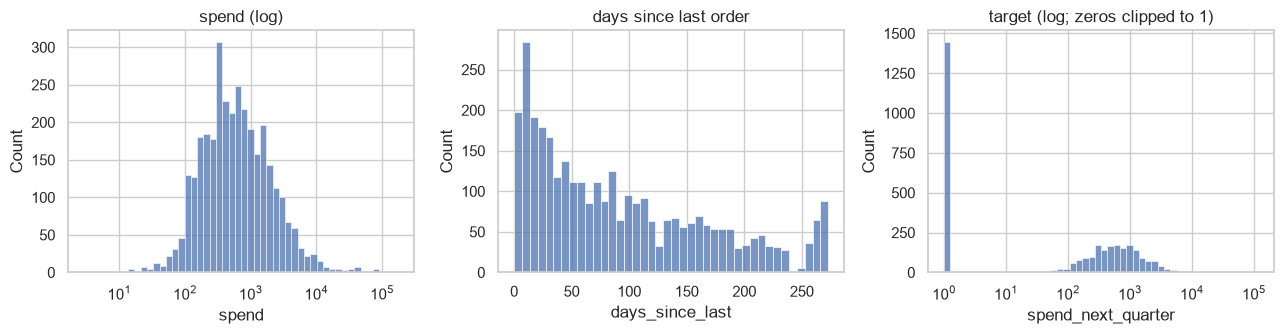

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.histplot(cust["spend"], bins=50, log_scale=True, ax=axes[0]); axes[0].set(title="spend (log)")
sns.histplot(cust["days_since_last"], bins=40, ax=axes[1]); axes[1].set(title="days since last order")
sns.histplot(cust["spend_next_quarter"].clip(lower=1), bins=50, log_scale=True, ax=axes[2]); axes[2].set(title="target (log; zeros clipped to 1)")
plt.tight_layout(); plt.show()

`spend` is log-normal-ish; `days_since_last` is spread across the whole 9 months; the target is the same shape as spend plus a wall of zeros. Plan: model `log1p(spend_next_quarter)`, or model `came_back` first and spend second (Module 02 and 03 do exactly this).

### Step 7: features vs target

In [16]:
cust.groupby("came_back")[["orders", "spend", "products", "avg_order", "tenure_days", "days_since_last", "recency_days"]].median().round(0)

,orders,spend,products,avg_order,tenure_days,days_since_last,recency_days
came_back,,,,,,,
0,1.0,342.0,19.0,239.0,167.0,111.0,204.0
1,3.0,870.0,42.0,304.0,198.0,47.0,24.0


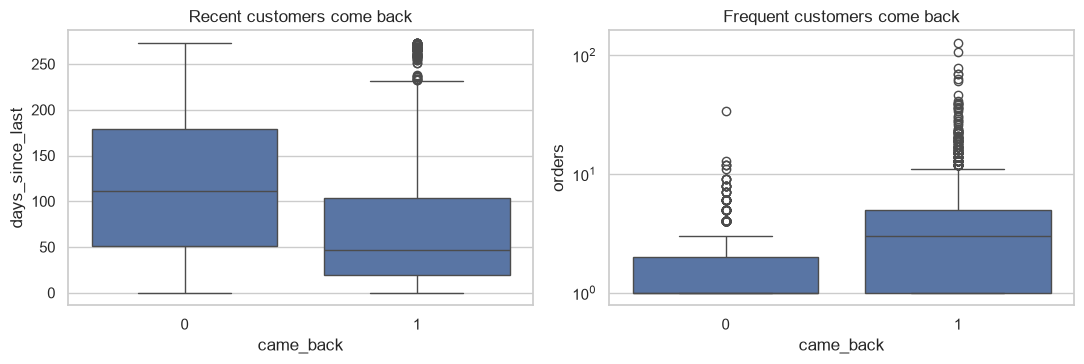

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=cust, x="came_back", y="days_since_last", ax=axes[0]); axes[0].set(title="Recent customers come back")
sns.boxplot(data=cust, x="came_back", y="orders", ax=axes[1]); axes[1].set(yscale="log", title="Frequent customers come back")
plt.tight_layout(); plt.show()

`days_since_last` and `orders` both separate the classes clearly: the RFM idea (Recency, Frequency, Monetary) that Module 04 formalises.

But look at `recency_days` in the table above: returning customers have a median of a few days, non-returners hundreds. That is far too good. Investigate.

### Step 8: redundancy and leakage

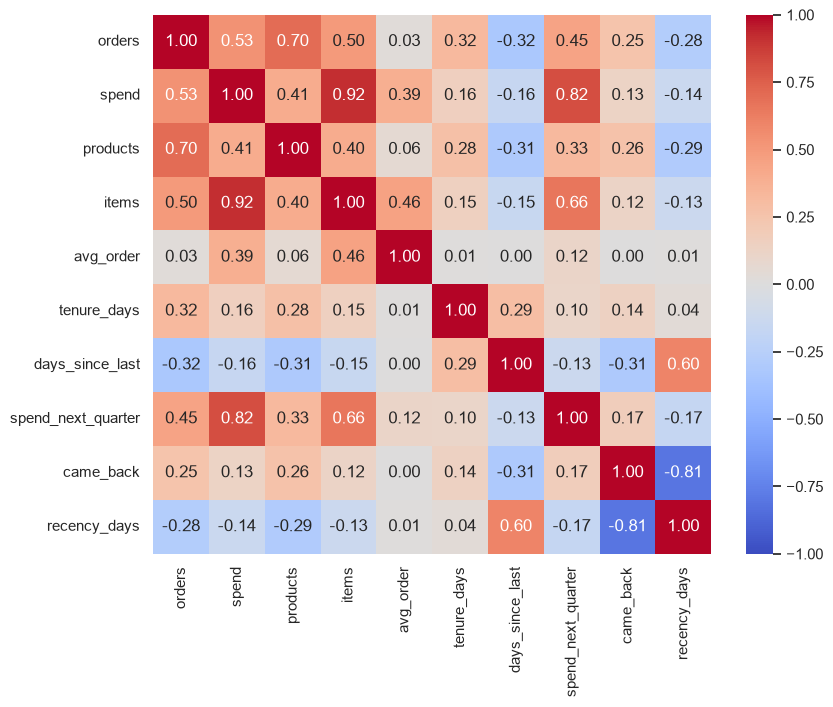

In [18]:
num = cust.drop(columns=["country"])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
plt.show()

In [19]:
print("correlation with came_back:")
print(num.corr()["came_back"].drop("came_back").sort_values().round(2))

correlation with came_back:
recency_days         -0.81
days_since_last      -0.31
avg_order             0.00
items                 0.12
spend                 0.13
tenure_days           0.14
spend_next_quarter    0.17
orders                0.25
products              0.26
Name: came_back, dtype: float64


Two things the heatmap shows:

1. **Redundancy.** `orders`, `products`, `items`, `spend` correlate 0.6–0.9 with each other. They all say "how much this customer buys". Keep one or two.
2. **Leakage.** `recency_days` has a correlation of about −0.8 with `came_back`, far stronger than any honest feature. Why? It was computed at *export time* (December 2011), *after* the target window. A customer who came back in October necessarily has a small `recency_days`. The column contains the answer. **Drop it.** `days_since_last`, computed at the cut-off date, is the honest version.

This is the single most common way real projects fail. The column had an innocent name and came from the same export as everything else.

In [20]:
cust = cust.drop(columns=["recency_days"])
cust.columns.tolist()

['orders',
 'spend',
 'products',
 'items',
 'country',
 'avg_order',
 'tenure_days',
 'days_since_last',
 'spend_next_quarter',
 'came_back']

### The written summary

> One row per customer (3,300); features from Dec 2010–Aug 2011, target from Sep–Nov 2011. No missing or duplicate rows. Regression target `spend_next_quarter` is right-skewed with a large spike at zero; plan `log1p` or a two-stage model. `came_back` is mildly imbalanced (about 56/44). `days_since_last` and `orders` are the strongest honest predictors. `orders`/`products`/`items`/`spend` are near-duplicates; keep `orders` and `spend`. `recency_days` was leakage (computed after the target window) and has been dropped. `country` is 90% UK; group the rest. Wholesale outliers exist in `spend`; keep but consider log scale.

Eight sentences. That is the deliverable of EDA.

## Quiz answers

1. What one row represents. Models predict one row at a time, so the rows must be the things you want predictions about (customers, not transactions).
2. Correlation with the target far stronger than any plausible feature; missing exactly when the target is one class; a name or timestamp implying it was recorded after the outcome.
3. Imbalanced-data techniques: class weights, resampling, and precision/recall instead of accuracy (05.7).
4. A log transform (`np.log1p`) of the target, so the model is not dominated by a few huge values.
5. Any decision based on test data (which features, which transformation, which outliers to drop) leaks information about the test set into the model, inflating its score.

**Next:** [01.P Mini-project](../project/)